# Method 1: Constraint propagation and backtracking
One variable per cell, with values 1 to NxN (or just the given value).
Rules: all values different, and every row, column and diagonal sums to M.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Problem
The magic constant, the 2N+2 lines, and a check for a finished square.

In [2]:
def magic_constant(n):
    return n * (n * n + 1) // 2


In [3]:
def get_lines(n):
    rows = [[i * n + j for j in range(n)] for i in range(n)]
    cols = [[i * n + j for i in range(n)] for j in range(n)]
    diag = [i * n + i for i in range(n)]
    anti = [i * n + (n - 1 - i) for i in range(n)]
    return rows + cols + [diag, anti]


In [4]:
def is_magic(square):
    square = np.array(square)
    n = len(square)
    flat = square.flatten()
    if sorted(flat.tolist()) != list(range(1, n * n + 1)):
        return False
    M = magic_constant(n)
    return all(flat[line].sum() == M for line in get_lines(n))


## Test puzzles
We take a known magic square, rotate or flip it, and keep a few cells as givens.

In [5]:
def siamese(n):
    #odd n: move up-right, go down when the cell is taken
    sq = np.zeros((n, n), dtype=int)
    i, j = 0, n // 2
    for v in range(1, n * n + 1):
        sq[i, j] = v
        if sq[(i - 1) % n, (j + 1) % n] == 0:
            i, j = (i - 1) % n, (j + 1) % n
        else:
            i = (i + 1) % n
    return sq


In [6]:
def doubly_even(n):
    sq = np.arange(1, n * n + 1).reshape(n, n)
    for i in range(n):
        for j in range(n):
            if (i % 4 in (0, 3)) == (j % 4 in (0, 3)):
                sq[i, j] = n * n + 1 - sq[i, j]
    return sq


In [7]:
def singly_even(n):
    h = n // 2
    a = siamese(h)
    sq = np.block([[a, a + 2 * h * h], [a + 3 * h * h, a + h * h]])
    k = (n - 2) // 4
    for i in range(h):
        cols = list(range(k)) + list(range(n - k + 1, n))
        if i == h // 2:
            cols = [c + 1 if c < k else c for c in cols]
        for j in cols:
            sq[i, j], sq[i + h, j] = sq[i + h, j], sq[i, j]
    return sq


In [8]:
def make_puzzle(n, n_given=0, seed=None):
    rng = np.random.default_rng(seed)
    if n % 2 == 1:
        sol = siamese(n)
    elif n % 4 == 0:
        sol = doubly_even(n)
    else:
        sol = singly_even(n)
    #rotating or flipping keeps the square magic, so puzzles differ by seed
    sol = np.rot90(sol, rng.integers(4))
    if rng.random() < 0.5:
        sol = np.fliplr(sol)
    sol = np.array(sol)
    puzzle = np.zeros((n, n), dtype=int)
    cells = rng.choice(n * n, size=n_given, replace=False)
    puzzle.flat[cells] = sol.flat[cells]
    return puzzle


## Checking the givens
Invalid givens (a repeated value, or a value outside 1…N²) are rejected before the search.

In [9]:
def check_givens(puzzle):
    puzzle = np.array(puzzle)
    n = len(puzzle)
    if puzzle.ndim != 2 or puzzle.shape[1] != n:
        return False
    given = puzzle[puzzle != 0].tolist()
    #0 means empty, so every given must be in 1..n*n and appear once
    in_range = all(1 <= v <= n * n for v in given)
    return in_range and len(given) == len(set(given))

## Constraint propagation
We cross off values that can't be part of a solution.
A value stays in a line only if the other free cells can still reach the missing sum.

In [10]:
def revise_line(D, line, M):
    free = [c for c in line if len(D[c]) > 1]
    R = M - sum(min(D[c]) for c in line if len(D[c]) == 1)
    k = len(free)
    if k == 0:
        return R == 0
    #last free cell: it must take exactly the missing value
    if k == 1:
        c = free[0]
        if R not in D[c]:
            return False
        D[c] = {R}
        return True

    U = sorted(set().union(*[D[c] for c in free]))
    if len(U) < k:
        return False

    low = sum(U[:k - 1])
    high = sum(U[-(k - 1):])
    for c in free:
        keep = set()
        for v in D[c]:
            #v cannot be used twice, so if it is among them take the next value
            lo = low - v + U[k - 1] if v <= U[k - 2] else low
            hi = high - v + U[-k] if v >= U[-(k - 1)] else high
            if lo <= R - v <= hi:
                keep.add(v)
        if not keep:
            return False
        D[c] = keep
    return True


In [11]:
def revise_alldiff(D):
    taken = [min(d) for d in D if len(d) == 1]
    if len(taken) != len(set(taken)):
        return False
    #a value fixed in one cell is removed from all the others
    taken = set(taken)
    for d in D:
        if len(d) > 1:
            d -= taken
            if not d:
                return False
    return True


In [12]:
def forward_check(D, var, value, lines_of, M):
    for c in range(len(D)):
        if c != var and value in D[c]:
            D[c].discard(value)
            if not D[c]:
                return False
    for line in lines_of[var]:
        if not revise_line(D, line, M):
            return False
    return True


In [13]:
def arc_consistency(D, lines, M):
    while True:
        size = sum(len(d) for d in D)
        if not revise_alldiff(D):
            return False
        for line in lines:
            if not revise_line(D, line, M):
                return False
        if sum(len(d) for d in D) == size:
            return True


## Backtracking
Depth-first search: fill the cell with fewest options, propagate, undo if a cell runs out of values.

In [14]:
def select_variable(D):
    free = [c for c in range(len(D)) if len(D[c]) > 1]
    return min(free, key=lambda c: len(D[c]))


In [15]:
def order_values(D, var, s):
    if s["value_order"] != "lcv":
        return sorted(D[var])
    size = sum(len(d) for d in D)
    score = {}
    for v in D[var]:
        #on large squares one ordering is slow, so check the time here too
        if time.time() > s["deadline"]:
            raise TimeoutError
        D2 = [set(d) for d in D]
        D2[var] = {v}
        if inference(D2, var, v, s):
            score[v] = size - sum(len(d) for d in D2)
        else:
            score[v] = float("inf")
    return sorted(D[var], key=lambda v: score[v])


In [16]:
def inference(D, var, value, s):
    if s["mode"] == "fc":
        return forward_check(D, var, value, s["lines_of"], s["M"])
    return arc_consistency(D, s["lines"], s["M"])


In [17]:
def is_goal(D, s):
    values = [min(d) for d in D]
    if len(set(values)) != len(values):
        return False
    return all(sum(values[c] for c in line) == s["M"] for line in s["lines"])


In [18]:
def backtrack(D, s):
    if time.time() > s["deadline"]:
        raise TimeoutError
    if all(len(d) == 1 for d in D):
        return D if is_goal(D, s) else None

    var = select_variable(D)
    for value in order_values(D, var, s):
        s["nodes"] += 1
        #work on a copy so the choice can be undone
        D2 = [set(d) for d in D]
        D2[var] = {value}
        if inference(D2, var, value, s):
            result = backtrack(D2, s)
            if result is not None:
                return result
        s["backtracks"] += 1
    return None


In [19]:
def backtracking_search(puzzle, mode="ac", value_order="lcv", time_limit=60):
    #reject invalid givens instead of searching
    if not check_givens(puzzle):
        return {"status": "invalid input", "square": None, "time": 0.0,
                "nodes": 0, "backtracks": 0}

    puzzle = np.array(puzzle)
    n = len(puzzle)
    lines = get_lines(n)
    s = {"M": magic_constant(n), "lines": lines,
         "lines_of": [[l for l in lines if c in l] for c in range(n * n)],
         "mode": mode, "value_order": value_order,
         "deadline": time.time() + time_limit, "nodes": 0, "backtracks": 0}

    D = [{int(x)} if x > 0 else set(range(1, n * n + 1)) for x in puzzle.flatten()]

    start = time.time()
    status, square = "fail", None
    try:
        if arc_consistency(D, lines, s["M"]):
            result = backtrack(D, s)
            if result is not None:
                square = np.array([min(d) for d in result]).reshape(n, n)
                status = "solved"
    except TimeoutError:
        status = "timeout"
    return {"status": status, "square": square, "time": time.time() - start,
            "nodes": s["nodes"], "backtracks": s["backtracks"]}


## Experiment 1a
One 4×4 puzzle, solved with the four settings. Every square is checked.

In [20]:
puzzle = make_puzzle(4, n_given=3, seed=1)
print("M =", magic_constant(4))
print(puzzle)


M = 34
[[13  0 12  0]
 [ 0  0  0 15]
 [ 0  0  0  0]
 [ 0  0  0  0]]


In [21]:
for mode in ["fc", "ac"]:
    for order in ["ascending", "lcv"]:
        r = backtracking_search(puzzle, mode=mode, value_order=order)
        ok = is_magic(r["square"]) and \
             bool(np.all((puzzle == 0) | (puzzle == r["square"])))
        print(f"\n{mode} + {order}: {r['status']}, {r['time']:.3f} s, "
              f"{r['nodes']} nodes, {r['backtracks']} backtracks, valid: {ok}")
        print(r["square"])



fc + ascending: solved, 0.033 s, 2286 nodes, 2280 backtracks, valid: True
[[13  3 12  6]
 [ 8 10  1 15]
 [ 2 16  7  9]
 [11  5 14  4]]

fc + lcv: solved, 0.018 s, 761 nodes, 755 backtracks, valid: True
[[13  3 12  6]
 [ 8 10  1 15]
 [ 2 16  7  9]
 [11  5 14  4]]

ac + ascending: solved, 0.013 s, 100 nodes, 97 backtracks, valid: True
[[13  3 12  6]
 [10  1  8 15]
 [ 7 16  9  2]
 [ 4 14  5 11]]

ac + lcv: solved, 0.013 s, 37 nodes, 34 backtracks, valid: True
[[13  5 12  4]
 [ 2 11  6 15]
 [ 3  8  9 14]
 [16 10  7  1]]


## Experiment 1b
Sizes 3 to 15 (N = 3–8, 10, 12, 15, the same for the three methods), with and without givens, 5 puzzles each, 10 seconds per run.
Without givens the puzzle is always the empty grid, so those runs only differ in time.

In [22]:
sizes = [3, 4, 5, 6, 7, 8, 10, 12, 15]
#5 puzzles per size (without givens they are all the empty grid)
seeds = range(5)
given_fractions = [0.0, 0.2]
settings = [("fc", "ascending"), ("fc", "lcv"), ("ac", "ascending"), ("ac", "lcv")]
time_limit = 10

rows = []
for n in sizes:
    for frac in given_fractions:
        for seed in seeds:
            puzzle = make_puzzle(n, n_given=int(frac * n * n), seed=seed)
            for mode, order in settings:
                r = backtracking_search(puzzle, mode, order, time_limit)
                ok = r["status"] == "solved" and is_magic(r["square"]) and \
                     bool(np.all((puzzle == 0) | (puzzle == r["square"])))
                rows.append({"N": n, "givens": frac, "seed": seed,
                             "setting": mode + " + " + order,
                             "solved": ok, "time": r["time"], "nodes": r["nodes"]})
    print("N =", n, "done")

results = pd.DataFrame(rows)
results.to_csv("results_alg1.csv", index=False)

N = 3 done
N = 4 done
N = 5 done
N = 6 done
N = 7 done
N = 8 done
N = 10 done
N = 12 done
N = 15 done


## Results table

In [23]:
summary = results.groupby(["givens", "setting", "N"]).agg(
    solved=("solved", "mean"),
    median_time=("time", "median"),
    median_nodes=("nodes", "median")).reset_index()
summary["solved"] = (100 * summary["solved"]).round().astype(int)
summary["median_time"] = summary["median_time"].round(3)
summary

,givens,setting,N,solved,median_time,median_nodes
0,0.0,ac + ascending,3,100,0.000,3.0
1,0.0,ac + ascending,4,100,0.003,20.0
2,0.0,ac + ascending,5,100,0.321,2045.0
3,0.0,ac + ascending,6,0,10.000,51851.0
4,0.0,ac + ascending,7,0,10.001,18550.0
...,...,...,...,...,...,...
67,0.2,fc + lcv,7,0,10.000,346353.0
68,0.2,fc + lcv,8,0,10.000,345710.0
69,0.2,fc + lcv,10,0,10.001,155575.0
70,0.2,fc + lcv,12,0,10.002,68894.0


## Plot

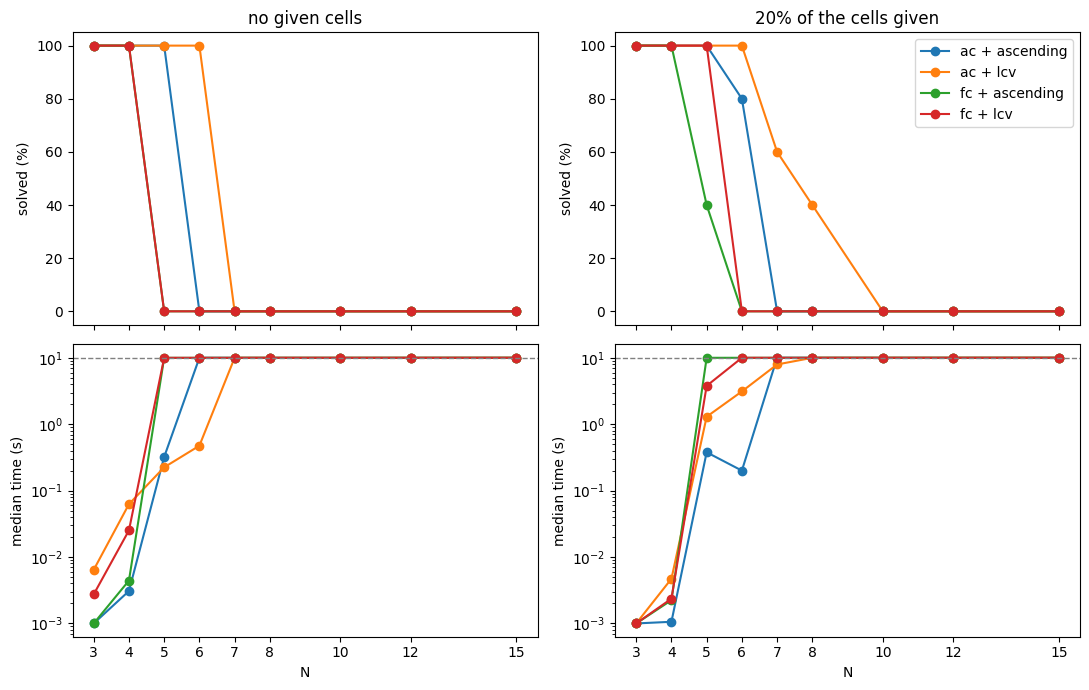

In [24]:
results = pd.read_csv("results_alg1.csv")
time_limit = 10

summary = results.groupby(["givens", "setting", "N"]).agg(
    solved=("solved", "mean"),
    median_time=("time", "median")).reset_index()
summary["solved"] = 100 * summary["solved"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for j, frac in enumerate([0.0, 0.2]):
    part = summary[summary["givens"] == frac]
    for setting, g in part.groupby("setting"):
        axes[0, j].plot(g["N"], g["solved"], marker="o", label=setting)
        #a time of 0 cannot be drawn on a log scale, so show it as 1 ms
        axes[1, j].plot(g["N"], g["median_time"].clip(lower=1e-3), marker="o", label=setting)
    axes[0, j].set_title("no given cells" if frac == 0 else "20% of the cells given")
    axes[0, j].set_ylabel("solved (%)")
    axes[0, j].set_ylim(-5, 105)
    axes[1, j].axhline(time_limit, color="grey", linestyle="--", linewidth=1)
    #log scale because times go from milliseconds to seconds
    axes[1, j].set_yscale("log")
    axes[1, j].set_ylabel("median time (s)")
    axes[1, j].set_xlabel("N")
    axes[1, j].set_xticks(sorted(results["N"].unique()))
axes[0, 1].legend()
plt.tight_layout()
plt.savefig("alg1_time.png", dpi=150)
plt.show()

## Correctness checks
Special cases and an independent check of every returned square (time limit 2 s).

In [25]:
def valid_square(square, puzzle):
    sq = np.array(square)
    puzzle = np.array(puzzle)
    n = len(sq)
    M = n * (n * n + 1) // 2
    values_ok = sorted(sq.flatten().tolist()) == list(range(1, n * n + 1))
    lines_ok = (all(sq.sum(axis=0) == M) and all(sq.sum(axis=1) == M)
                and np.trace(sq) == M and np.trace(np.fliplr(sq)) == M)
    givens_ok = bool(np.all((puzzle == 0) | (puzzle == sq)))
    return values_ok and lines_ok and givens_ok

In [26]:
full = make_puzzle(4, n_given=16, seed=0)
one_empty = full.copy()
one_empty[0, 0] = 0
two_empty = one_empty.copy()
two_empty[3, 2] = 0
cases = {
    "repeated given": [[1, 1, 0], [0, 0, 0], [0, 0, 0]],
    "given out of range": [[10, 0, 0], [0, 0, 0], [0, 0, 0]],
    "impossible givens": [[0, 0, 0], [0, 1, 0], [0, 0, 0]],
    "complete square": full,
    "1 empty cell": one_empty,
    "2 empty cells": two_empty,
}

In [27]:
for name, p in cases.items():
    r = backtracking_search(p, time_limit=2)
    valid = r["square"] is not None and valid_square(r["square"], p)
    print(f"{name:20s} {r['status']:14s} {r['time']:5.2f} s   valid square: {valid}")

repeated given       invalid input   0.00 s   valid square: False
given out of range   invalid input   0.00 s   valid square: False
impossible givens    fail            0.00 s   valid square: False
complete square      solved          0.00 s   valid square: True
1 empty cell         solved          0.00 s   valid square: True
2 empty cells        solved          0.00 s   valid square: True


In [28]:
runs, checked, wrong = 0, 0, 0
for n in [3, 4]:
    for frac in [0.0, 0.2]:
        for seed in range(5):
            p = make_puzzle(n, n_given=int(frac * n * n), seed=seed)
            r = backtracking_search(p, time_limit=2)
            runs += 1
            if r["status"] == "solved":
                checked += 1
                wrong += not valid_square(r["square"], p)
print(f"{checked} of {runs} runs solved, {wrong} wrong squares")

20 of 20 runs solved, 0 wrong squares
